### **EN3150 Assignment 03 — Model A: Standard CNN**
#### **Resource-Constrained CNN for Edge Image Classification**
This notebook implements **Model A**, a standard convolutional neural network (CNN) for Fashion-MNIST image classification.
##### **Objectives**
1. Load the preprocessed Fashion-MNIST dataset.
2. Verify the dataset dimensions and class distribution.
3. Design a standard CNN using:
   - Standard 2D convolutional layers
   - ReLU activation
   - Max-pooling layers
   - Fully connected layers
4. Calculate and verify the total number of trainable parameters.
5. Select and justify the optimizer and learning rate.
6. Train the model for at least 20 epochs.
7. Plot training and validation loss curves.
8. Evaluate the model on the test set.
9. Calculate accuracy, precision, and recall.
10. Generate and analyze the confusion matrix.
11. Record model size and training time per epoch.

The preprocessing stage has already been completed in a separate notebook.
Therefore, this notebook loads the saved processed dataset rather than repeating
the preprocessing steps.

#### **1. Import Required Libraries**

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

keras = tf.keras
layers = tf.keras.layers

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score
)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

TensorFlow version: 2.22.0-rc0
NumPy version: 2.5.1


#### **2. Load the Preprocessed Dataset**

In [6]:
# Path to the processed dataset
DATA_PATH = "../data/processed/fashion_mnist_processed.npz"

# Check that the dataset exists
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Processed dataset not found at: {DATA_PATH}\n"
        "Please make sure the preprocessing notebook has generated the dataset."
    )

# Load processed data
data = np.load(DATA_PATH)

X_train = data["X_train"]
y_train = data["y_train"]

X_val = data["X_val"]
y_val = data["y_val"]

X_test = data["X_test"]
y_test = data["y_test"]

print("Processed dataset loaded successfully.")

Processed dataset loaded successfully.


#### **3. Verify Dataset Dimension**

In [7]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nPixel value range:")
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

X_train shape: (49000, 28, 28, 1)
y_train shape: (49000,)
X_val shape: (10500, 28, 28, 1)
y_val shape: (10500,)
X_test shape: (10500, 28, 28, 1)
y_test shape: (10500,)

Pixel value range:
Minimum: 0.0
Maximum: 1.0


In [8]:
# Class names
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Number of classes:", len(class_names))

for i, name in enumerate(class_names):
    print(f"{i}: {name}")

Number of classes: 10
0: T-shirt/top
1: Trouser
2: Pullover
3: Dress
4: Coat
5: Sandal
6: Shirt
7: Sneaker
8: Bag
9: Ankle boot


#### **4. Sample Images**

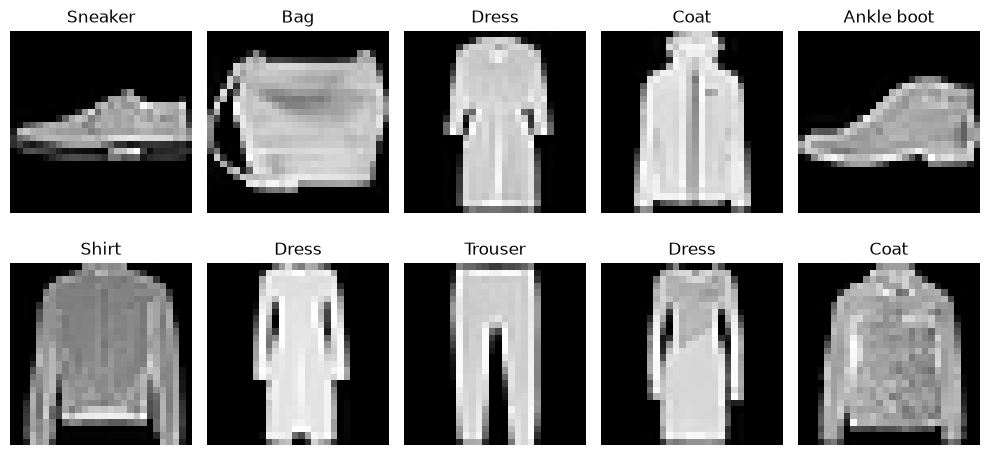

In [9]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

#### **5. Model A — Standard CNN Architecture**

Model A is designed as a conventional CNN using standard 2D convolutional
operations followed by max-pooling layers.

##### ***Architecture***

| Layer | Configuration |
|---|---|
| Input | 28 × 28 × 1 |
| Conv2D | 16 filters, 3 × 3, ReLU |
| MaxPooling2D | 2 × 2 |
| Conv2D | 32 filters, 3 × 3, ReLU |
| MaxPooling2D | 2 × 2 |
| Conv2D | 64 filters, 3 × 3, ReLU |
| MaxPooling2D | 2 × 2 |
| Flatten | — |
| Dense | 64 units, ReLU |
| Output Dense | 10 units, Softmax |

The architecture follows the assignment requirement for Model A: standard
2D convolutional layers interleaved with max-pooling layers.

In [10]:
model_A = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Convolution block 1
    layers.Conv2D(
        filters=16,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Convolution block 2
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Convolution block 3
    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_A.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,874 (237.79 KB)

 Trainable params: 60,874 (237.79 KB)

 Non-trainable params: 0 (0.00 B)

##### ***5.1 Architecture Explanation***
The network progressively increases the number of convolutional filters from
16 to 32 and then to 64. This allows the network to learn increasingly complex
visual features.

##### **Convolutional layers**
The convolutional layers extract spatial features from the input image.
A 3 × 3 kernel is used because it provides a small receptive field while
keeping the number of parameters relatively low.

##### **Max-pooling layers**
A 2 × 2 max-pooling operation reduces the spatial dimensions by approximately
half after each convolutional block. This reduces the computational burden
of subsequent layers while retaining strong local features.

##### **Flatten layer**
After the three pooling operations, the feature map is flattened into a
one-dimensional vector before being passed to the fully connected classifier.

##### **Fully connected layers**
A 64-unit dense layer combines the extracted features for classification.
The final 10-unit layer corresponds to the 10 Fashion-MNIST classes.

#### ***5.2 Trainable Parameter Calculation***

For a standard convolutional layer:

$$
P = (K_h \times K_w \times C_{in} \times C_{out}) + C_{out}
$$

where:

* $K_h, K_w$ = kernel height and width
* $C_{in}$ = number of input channels
* $C_{out}$ = number of filters
* $C_{out}$ additional parameters correspond to the biases

##### **Conv2D Layer 1**

$$
(3 \times 3 \times 1 \times 16) + 16 = 160
$$

##### **Conv2D Layer 2**

$$
(3 \times 3 \times 16 \times 32) + 32 = 4,640
$$

##### **Conv2D Layer 3**

$$
(3 \times 3 \times 32 \times 64) + 64 = 18,496
$$

After three $2 \times 2$ pooling operations:

$$
28 \rightarrow 14 \rightarrow 7 \rightarrow 3
$$

Therefore, the final feature map is:

$$
3 \times 3 \times 64 = 576
$$

##### **Dense Layer**

$$
(576 \times 64) + 64 = 36,928
$$

##### **Output Layer**

$$
(64 \times 10) + 10 = 650
$$

##### **Total**

$$
\begin{aligned}
160 + 4,640 + 18,496 + 36,928 + 650
&= 60,874
\end{aligned}
$$

Therefore, Model A contains **60,874 trainable parameters**.


In [11]:
manual_parameter_count = (
    160 +
    4640 +
    18496 +
    36928 +
    650
)

keras_parameter_count = model_A.count_params()

print("Manual parameter count :", manual_parameter_count)
print("Keras parameter count  :", keras_parameter_count)

if manual_parameter_count == keras_parameter_count:
    print("Parameter count verification: PASSED")
else:
    print("Parameter count verification: FAILED")

Manual parameter count : 60874
Keras parameter count  : 60874
Parameter count verification: PASSED


#### ***5.3 Activation Function Selection***

##### ReLU
ReLU is computationally simple because it mainly requires a comparison with
zero and does not require an exponential calculation.

##### Softmax
Softmax is used only in the final output layer to convert the 10 output logits
into class probabilities.


#### **6. Optimizer Selection**
Adam is selected as the primary optimizer for Model A.

The selected optimizer will later be compared with:

1. Standard SGD
2. SGD with Momentum

In [12]:
learning_rate_A = 0.001

model_A.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=learning_rate_A
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model A compiled successfully.")
print("Optimizer: Adam")
print("Learning rate:", learning_rate_A)

Model A compiled successfully.
Optimizer: Adam
Learning rate: 0.001


#### **7. Model A Training**

The model is trained for **20 epochs**, satisfying the minimum training
requirement of the assignment. The validation set is used during training to monitor generalization
performance without using the test set for model development.


In [13]:
EPOCHS = 20
BATCH_SIZE = 64

start_time = time.time()

history_A = model_A.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

total_training_time_A = time.time() - start_time

average_epoch_time_A = total_training_time_A / EPOCHS

print("\nTraining completed.")
print(f"Total training time: {total_training_time_A:.2f} seconds")
print(f"Average time per epoch: {average_epoch_time_A:.2f} seconds")

Epoch 1/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 19s 23ms/step - accuracy: 0.7891 - loss: 0.5824 - val_accuracy: 0.8560 - val_loss: 0.3959
Epoch 2/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8722 - loss: 0.3528 - val_accuracy: 0.8801 - val_loss: 0.3351
Epoch 3/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.8894 - loss: 0.3013 - val_accuracy: 0.8861 - val_loss: 0.3156
Epoch 4/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - accuracy: 0.9012 - loss: 0.2710 - val_accuracy: 0.8935 - val_loss: 0.2951
Epoch 5/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9095 - loss: 0.2488 - val_accuracy: 0.8999 - val_loss: 0.2812
Epoch 6/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.9153 - loss: 0.2308 - val_accuracy: 0.9023 - val_loss: 0.2735
Epoch 7/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 15s 20ms/step - accuracy: 0.9217 - loss: 0.2138 - val_accuracy: 0.9012 - val_loss: 0.2775
Epoch 8/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.9267 - loss: 0.1999 - 

##### ***7.1 Training History***

The training history contains the loss and accuracy values recorded for both
the training and validation datasets at every epoch.

In [14]:
history_df_A = pd.DataFrame(history_A.history)
history_df_A.index = np.arange(1, EPOCHS + 1)
history_df_A.head()

,accuracy,loss,val_accuracy,val_loss
1,0.789061,0.582355,0.856000,0.395852
2,0.872204,0.352796,0.880095,0.335122
3,0.889408,0.301295,0.886095,0.315609
4,0.901204,0.271026,0.893524,0.295064
5,0.909531,0.248785,0.899905,0.281183


##### ***7.2 Training and Validation Loss***

The following graph shows how the training and validation loss changed during
the 20 training epochs.

A decreasing training loss indicates that the model is learning from the
training data. The validation loss provides an indication of how well the
learned model generalizes to unseen validation data.

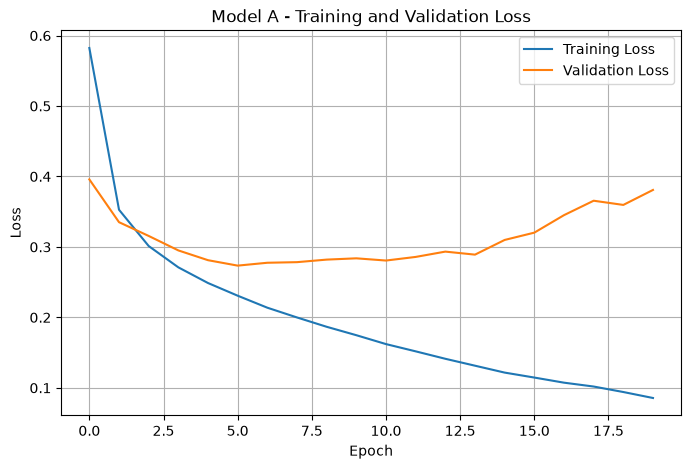

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_A.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_A.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model A - Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

##### ***7.3 Training and Validation Accuracy***

Although the assignment specifically requires loss curves, accuracy curves are
also plotted to make the training behaviour easier to interpret.

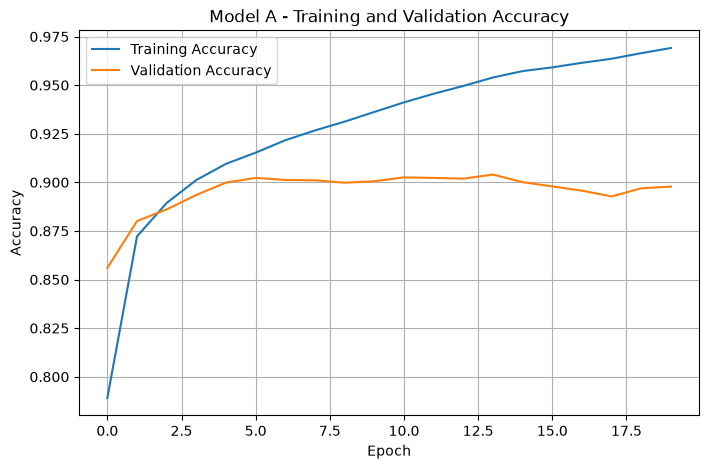

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_A.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_A.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model A - Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

#### **8. Model A Test Evaluation**
The test set is evaluated only after training is completed.
The following metrics are recorded:
- Test loss
- Test accuracy
- Precision
- Recall
- Confusion matrix

In [17]:
test_loss_A, test_accuracy_A = model_A.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"\nModel A Test Loss: {test_loss_A:.4f}")
print(f"Model A Test Accuracy: {test_accuracy_A:.4f}")
print(f"Model A Test Accuracy: {test_accuracy_A * 100:.2f}%")

329/329 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9006 - loss: 0.3636

Model A Test Loss: 0.3636
Model A Test Accuracy: 0.9006
Model A Test Accuracy: 90.06%


In [18]:
# Generate predictions on the test set
y_pred_probability_A = model_A.predict(
    X_test,
    verbose=1
)

y_pred_A = np.argmax(
    y_pred_probability_A,
    axis=1
)

print("Predictions generated successfully.")
print("Prediction shape:", y_pred_A.shape)

329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Predictions generated successfully.
Prediction shape: (10500,)


##### ***8.1 Precision and Recall***

In [19]:
precision_A = precision_score(
    y_test,
    y_pred_A,
    average="weighted"
)

recall_A = recall_score(
    y_test,
    y_pred_A,
    average="weighted"
)

print(f"Weighted Precision: {precision_A:.4f}")
print(f"Weighted Recall:    {recall_A:.4f}")

Weighted Precision: 0.9043
Weighted Recall:    0.9006


In [20]:
# Classification report
print(
    classification_report(
        y_test,
        y_pred_A,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.90      0.76      0.82      1050
     Trouser       0.95      1.00      0.97      1050
    Pullover       0.82      0.91      0.86      1050
       Dress       0.89      0.90      0.89      1050
        Coat       0.91      0.78      0.84      1050
      Sandal       0.97      0.99      0.98      1050
       Shirt       0.70      0.79      0.74      1050
     Sneaker       0.98      0.91      0.95      1050
         Bag       0.99      0.98      0.99      1050
  Ankle boot       0.94      0.99      0.96      1050

    accuracy                           0.90     10500
   macro avg       0.90      0.90      0.90     10500
weighted avg       0.90      0.90      0.90     10500



##### ***8.2 Confusion Matrix***

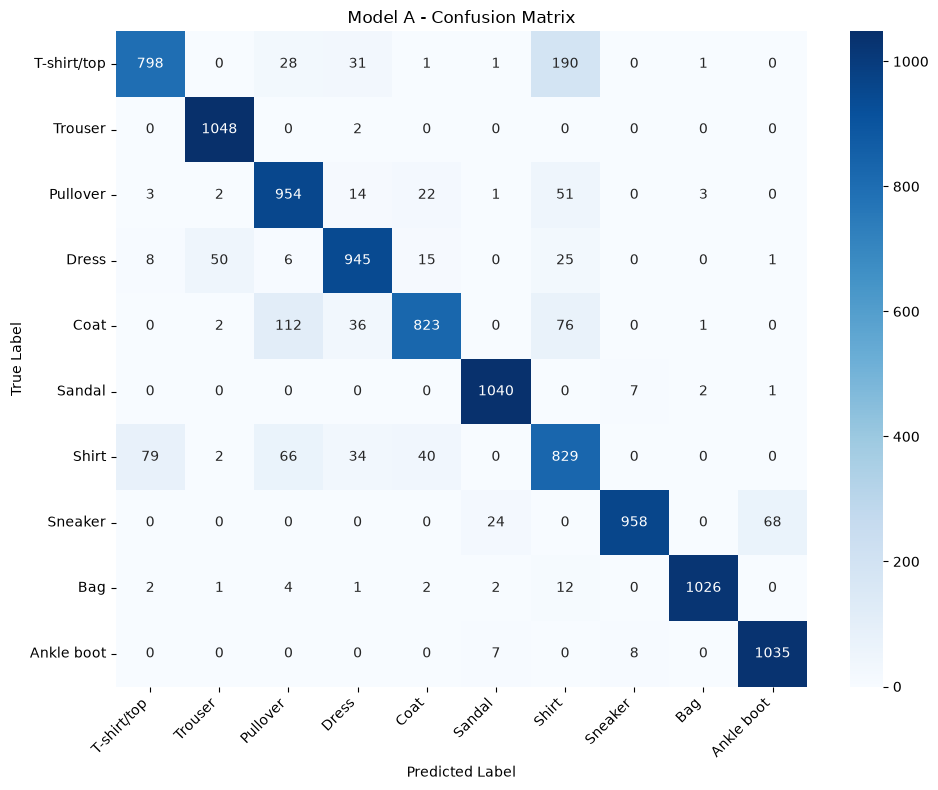

In [21]:
cm_A = confusion_matrix(
    y_test,
    y_pred_A
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_A,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Model A - Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#### **9. Model Size and Computational Information**

In [30]:
import os

MODEL_A_PATH = "../models/model_A.keras"

os.makedirs("../models", exist_ok=True)

model_A.save(MODEL_A_PATH)

print("Model A saved to:")
print(os.path.abspath(MODEL_A_PATH))

model_A_file_size_bytes = os.path.getsize(MODEL_A_PATH)
model_A_file_size_kb = model_A_file_size_bytes / 1024

print("Model A trainable parameters:", model_A.count_params())
print(f"Model A file size: {model_A_file_size_kb:.2f} KB")
print(f"Average training time per epoch: {average_epoch_time_A:.2f} seconds")

Model A saved to:
c:\Desktop\SEM 5\Pattern\EN3150-CNN-Classification\models\model_A.keras
Model A trainable parameters: 60874
Model A file size: 757.88 KB
Average training time per epoch: 13.49 seconds


#### **10. Model A Summary**
The following table summarizes the main quantitative results of Model A.

In [23]:
model_A_results = pd.DataFrame({
    "Model": ["Model A - Standard CNN"],
    "Trainable Parameters": [model_A.count_params()],
    "Model Size (KB)": [model_A_file_size_kb],
    "Training Time per Epoch (s)": [average_epoch_time_A],
    "Test Accuracy (%)": [test_accuracy_A * 100],
    "Weighted Precision": [precision_A],
    "Weighted Recall": [recall_A]
})

model_A_results

,Model,Trainable Parameters,Model Size (KB),Training Time per Epoch (s),Test Accuracy (%),Weighted Precision,Weighted Recall
0,Model A - Standard CNN,60874,757.881836,13.489936,90.057141,0.904349,0.900571


In [24]:
# Verify final results
print("========== MODEL A FINAL RESULTS ==========")
print(f"Trainable parameters : {model_A.count_params():,}")
print(f"Model size           : {model_A_file_size_kb:.2f} KB")
print(f"Total training time  : {total_training_time_A:.2f} s")
print(f"Time per epoch       : {average_epoch_time_A:.2f} s")
print(f"Test loss            : {test_loss_A:.4f}")
print(f"Test accuracy        : {test_accuracy_A * 100:.2f}%")
print(f"Weighted precision   : {precision_A:.4f}")
print(f"Weighted recall      : {recall_A:.4f}")
print("===========================================")

========== MODEL A FINAL RESULTS ==========
Trainable parameters : 60,874
Model size           : 757.88 KB
Total training time  : 269.80 s
Time per epoch       : 13.49 s
Test loss            : 0.3636
Test accuracy        : 90.06%
Weighted precision   : 0.9043
Weighted recall      : 0.9006


In [26]:
# Save results for later comparison

import os

# Create results directory at project root
RESULTS_PATH = "../results/model_A"

os.makedirs(RESULTS_PATH, exist_ok=True)

# Save Model A summary results
model_A_results.to_csv(
    os.path.join(RESULTS_PATH, "model_A_results.csv"),
    index=False
)

# Save training history
history_df_A.to_csv(
    os.path.join(RESULTS_PATH, "model_A_training_history.csv"),
    index=False
)

print("Model A results saved successfully.")
print("Results saved to:")
print(os.path.abspath(RESULTS_PATH))

Model A results saved successfully.
Results saved to:
c:\Desktop\SEM 5\Pattern\EN3150-CNN-Classification\results\model_A


#### **11. Model A Interpretation**

Model A was implemented using three standard 2D convolutional layers with
16, 32, and 64 filters respectively. Each convolutional layer was followed
by a 2 × 2 max-pooling operation. The extracted features were then passed
through a 64-unit fully connected layer and a 10-unit output layer.

ReLU was selected for the hidden layers.  Softmax was retained for the final classification layer to
produce probabilities across the ten classes.

Adam with a learning rate of 0.001 was selected as the initial optimizer.
The model was trained for 20 epochs using the predefined training and validation sets.

Based on the training and validation curves, the behaviour of the model can
be assessed in terms of convergence and possible overfitting. The test-set
accuracy, precision, recall, and confusion matrix provide the final
classification performance.

The measured training time per epoch and saved model size will be used later
to compare Model A against Model B.

#### **12. Misclassified Examples**


Number of misclassified test images: 1044


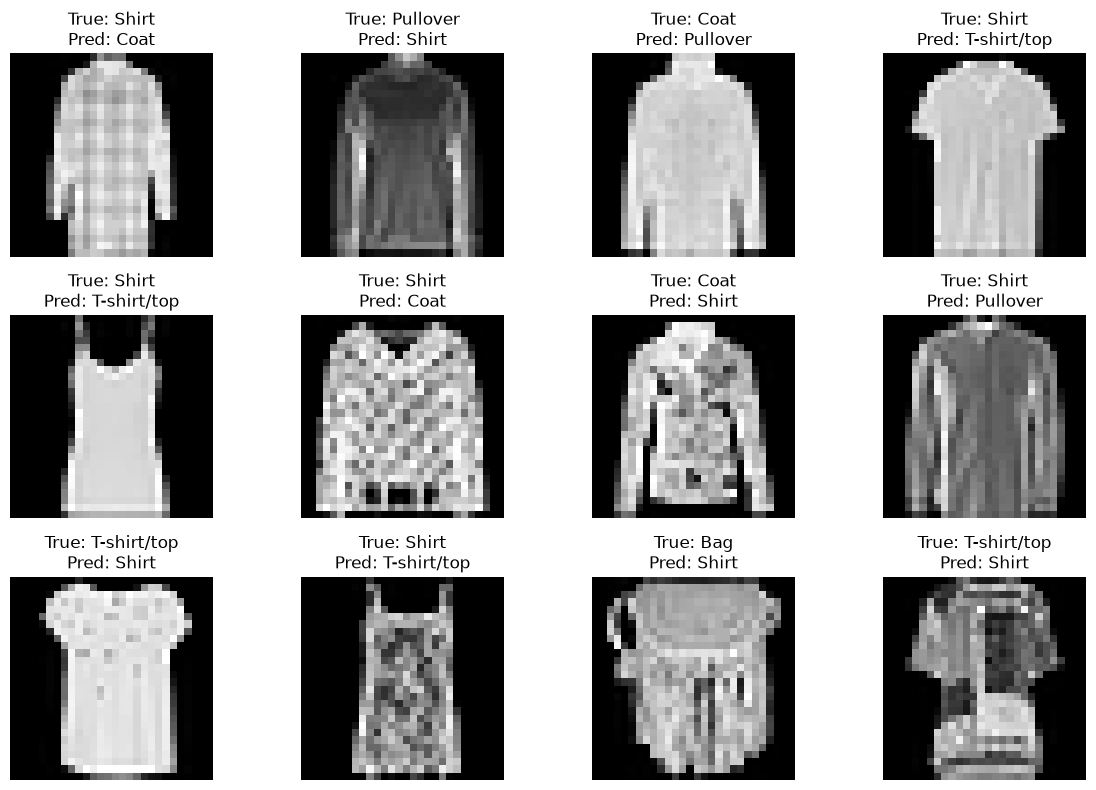

In [27]:
misclassified_indices = np.where(y_pred_A != y_test)[0]

print("Number of misclassified test images:", len(misclassified_indices))

plt.figure(figsize=(12, 8))

num_examples = min(12, len(misclassified_indices))

for i in range(num_examples):
    idx = misclassified_indices[i]

    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[idx].squeeze(), cmap="gray")

    plt.title(
        f"True: {class_names[y_test[idx]]}\n"
        f"Pred: {class_names[y_pred_A[idx]]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

#### **13. Conclusion**

Model A successfully implements the required standard CNN architecture using
standard 2D convolutions and max-pooling.

The model architecture, trainable parameter count, activation functions,
optimizer configuration, training behaviour, test performance, confusion
matrix, precision, recall, model size, and training time have been recorded.

The resulting Model A measurements will be used as the baseline for comparison
with Model B, which replaces standard convolutions with depthwise-separable
convolutions.

The next stage is to develop Model B while maintaining the same dataset
splits and evaluation methodology.

In [34]:
import sys
import os

PROJECT_ROOT = os.path.abspath("..")

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.model_A import build_model_A

model_A = build_model_A()
model_A.summary()

Model: "Model_A_Standard_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,874 (237.79 KB)

 Trainable params: 60,874 (237.79 KB)

 Non-trainable params: 0 (0.00 B)